In [76]:
import os
import glob

import numpy as np
import cv2
import matplotlib.pyplot as plt
import imagesize

(-0.5, 639.5, 479.5, -0.5)

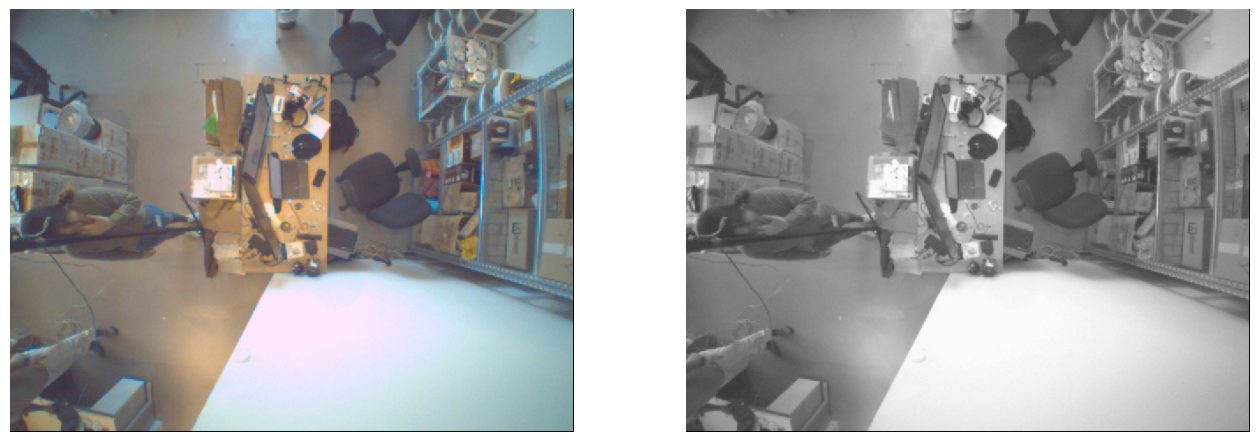

In [25]:
referece_img = cv2.imread('quality_reduce_comparison/cam4_poc_part1/images/val/250_cam4_.jpg')
referece_img = cv2.cvtColor(referece_img, cv2.COLOR_BGR2RGB)
referece_gray_img = cv2.cvtColor(referece_img, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.imshow(referece_img)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(referece_gray_img, cmap='gray')
plt.axis('off')


In [26]:
BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15/images"

img_paths = []
for i in ["train", "val", "tst", "holdout", "algotest"]:
    pth = os.path.join(BASE_PTH, i)
    img_paths += [os.path.join(pth, j) for j in glob.glob(os.path.join(pth, "*.jpg"))]

print(len(img_paths))

119834


In [61]:
list(img_paths).index('/home/klymy/data/people_detection/filtered_v3_margin_15/images/train/PG1_DL_H250_Office_MR_1495117403_01900.jpg')

185

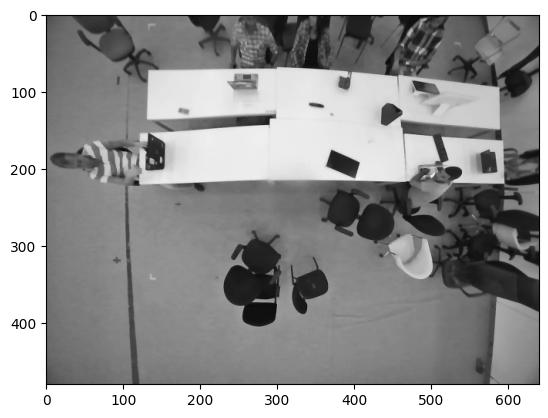

In [62]:
idx = 185
tmp_img = cv2.imread(img_paths[idx])
tmp_img = cv2.resize(tmp_img, (referece_img.shape[1], referece_img.shape[0]), cv2.INTER_AREA)
plt.imshow(cv2.cvtColor(tmp_img, cv2.COLOR_BGR2RGB))

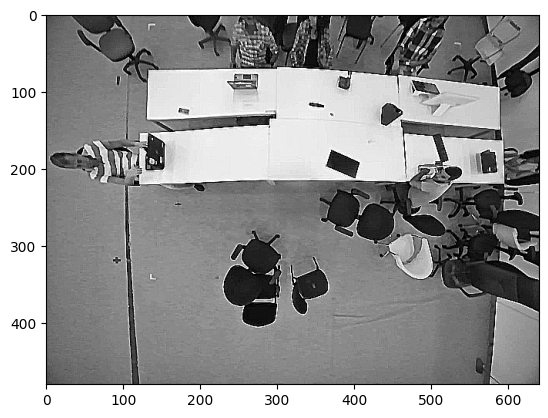

In [72]:
# Create the sharpening kernel 
kernel = np.array([
    [-1, -1, -1],
    [-1,  9, -1],
    [-1, -1, -1]
]) 
  
# Sharpen the image 
sharpened_image = cv2.filter2D(tmp_img, -1, kernel)
plt.imshow(cv2.cvtColor(sharpened_image, cv2.COLOR_BGR2RGB))

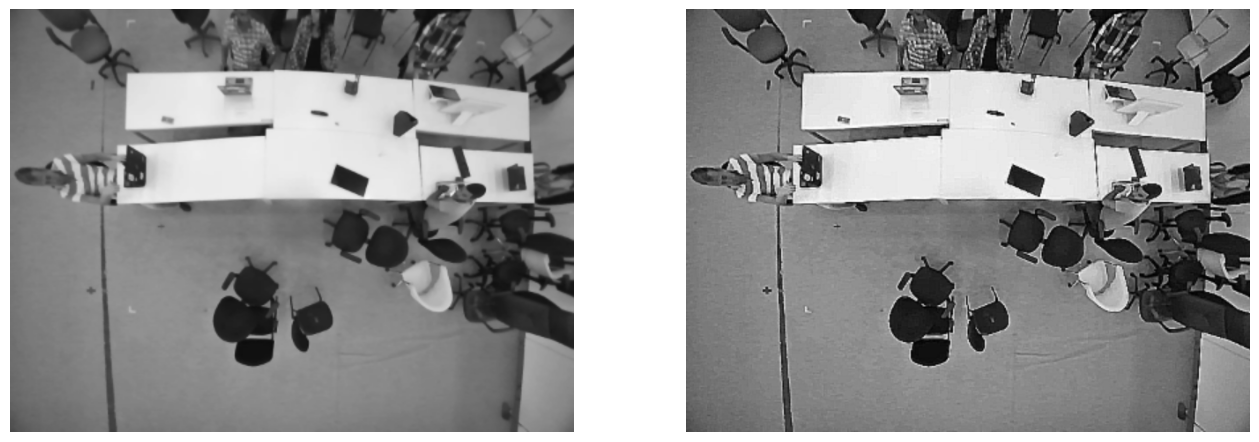

In [74]:
def pixelize(img: np.ndarray, scale_factor: float = 2) -> np.ndarray:
    """
    Pixelize the image by scaling it down and up.
    """
    # Downscale the image
    img = cv2.resize(img, None, fx=1/scale_factor, fy=1/scale_factor, interpolation=cv2.INTER_LINEAR)
    # Upscale the image
    img = cv2.resize(img, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_LINEAR)
    return img

scale_factor = 1.5
pixelized_image = pixelize(tmp_img, scale_factor=scale_factor)
pixelized_sharp_image = pixelize(sharpened_image, scale_factor=scale_factor)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(pixelized_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(pixelized_sharp_image, cv2.COLOR_BGR2RGB))
plt.axis('off');

In [77]:
sizes = set()
for img_pth in img_paths:
    sizes.add(imagesize.get(img_pth))

In [78]:
sizes

{(640, 480), (1280, 960)}